In [41]:
%pip install matplotlib numpy scipy opencv-python scikit-image

Note: you may need to restart the kernel to use updated packages.


## Image Restoration Techniques

In this section of the noteobook we aim to demonstrate the method of inverse filtering as one of the ways of performing image restoration.

For this we assume that the distorted image follows the form:

$$g(x, y) = H[f(x, y)] + n(x, y)$$

Where H is the degradation model and n(x, y) is added noise. If we assume this model is linear and position invariant (which is a good approximation for various types of real life scenarios), we can then take the DFT of both sides to get:

$$

G(u, v) = H(u, v) \cdot F(u, v) + N(u, v)

$$

In order to eliminate the effects of the distortion model, we can obtain back f(x, y) by taking the IDFT of the signal:

$$

F(u, v) = \frac{G(u, v) - N(u, v)}{H(u, v)}

$$


If the noise is now and we know the degradation model, then we can perfectly restore the original image. However, if the noise term is present then the noise spectrum divided by the degradation model can diverge for values where the degradation model equals zero. This is happens more often than not considering most degradation models are variants of low pass filters. In order to overcome this, we can implement a threshold culling on filter where we discard values that are smaller than the set threshold.

We will then compare it to other implementations

In [42]:
IMG_PATH = 'walk.jpg'

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sp
import cv2
from skimage import restoration, data
from skimage.metrics import mean_squared_error

In [53]:
def psf2otf(psf, shape):
    """
    Convierte una PSF espacial en su representación
    frecuencial OTF del tamaño de la imagen.
    """

    padded = np.zeros(shape)

    padded[:psf.shape[0], :psf.shape[1]] = psf

    for axis, axis_size in enumerate(psf.shape):
        padded = np.roll(
            padded,
            -axis_size // 2,
            axis=axis
        )

    return np.fft.fft2(padded)

In [44]:
def ShowImage(image, title='', vmin=None, vmax=None):
    plt.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.axis('off')
    plt.show()

In [45]:
def MotionBlurKernel(size, angle):
    # Create a motion blur kernel of given size and angle
    kernel = np.zeros((size, size))
    center = size // 2
    angle_rad = np.deg2rad(angle)
    
    for i in range(size):
        x = int(center + (i - center) * np.cos(angle_rad))
        y = int(center + (i - center) * np.sin(angle_rad))
        if 0 <= x < size and 0 <= y < size:
            kernel[y, x] = 1
            
    kernel /= np.sum(kernel)  # Normalize the kernel
    return kernel

In [46]:
def GaussianBlurKernel(size, sigma):
    # Create a Gaussian blur kernel of given size and sigma
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel /= np.sum(kernel)  # Normalize the kernel
    return kernel

In [47]:
def ApplyDegradation(image, kernel):
    # Apply degradation to the image using the given kernel
    degraded_image = cv2.filter2D(image, -1, kernel)
    return degraded_image

In [48]:
def AddGaussianNoise(image, mean=0, std:float =10):
    # Add Gaussian noise to the image
    noise = np.random.normal(mean, std, image.shape)
    noisy_image = image + noise
    noisy_image = np.clip(noisy_image, 0, 255)  # Clip values to valid range
    return noisy_image

In [66]:
def InverseFilter(degraded_image, kernel, threshold=1e-3):
    # Apply inverse filtering to the degraded image
    kernel_fft = np.fft.fft2(kernel, s=degraded_image.shape) + 1e-10  # Avoid division by zero
    #ShowImage(np.abs(kernel_fft), title='Kernel FFT Magnitude')
    degraded_fft = np.fft.fft2(degraded_image)
    #ShowImage(20 * np.log(np.abs(degraded_fft) + 1e-10), title='Degraded Image FFT Magnitude')
    
    restored_fft = np.where(np.abs(kernel_fft) > threshold, degraded_fft / kernel_fft, 0)
    restored_image = np.abs(np.fft.ifft2(restored_fft))

    #ShowImage(20 * np.log(np.abs(restored_fft) + 1e-10), title='Restored Image FFT Magnitude')

    # Clip values to valid range
    restored_image = np.clip(restored_image, 0, 1)
    return restored_image

In [50]:
def RichardsonLucy(degraded_image, kernel, iterations=30):
    # Apply Richardson-Lucy deconvolution to the degraded image
    restored_image = restoration.richardson_lucy(degraded_image, kernel, num_iter=iterations)
    restored_image /= np.max(restored_image)  # Normalize the restored image
    return restored_image

In [60]:
def WienerFilter(degraded_image, kernel, K=0.01):
    # Apply Wiener filtering to the degraded image
    kernel_fft = np.fft.fft2(kernel, s=degraded_image.shape)
    degraded_fft = np.fft.fft2(degraded_image)
    
    kernel_conj = np.conj(kernel_fft)
    wiener_filter = kernel_conj / (np.abs(kernel_fft)**2 + K)
    
    restored_fft = wiener_filter * degraded_fft
    restored_image = np.abs(np.fft.ifft2(restored_fft))

    # Clip values to valid range
    restored_image = np.clip(restored_image, 0, 1)
    return restored_image

In [57]:
def TikhonovRestore(degraded_image, kernel, alpha=0.01):
    # Apply Tikhonov regularization to the degraded image
    kernel_fft = np.fft.fft2(kernel, s=degraded_image.shape)
    degraded_fft = np.fft.fft2(degraded_image)

    laplacian = np.array([
        [0, -1,  0],
        [-1, 4, -1],
        [0, -1,  0]
    ])

    L = psf2otf(laplacian, degraded_image.shape)
    
    kernel_conj = np.conj(kernel_fft)

    F_hat = (kernel_conj * degraded_fft) / (np.abs(kernel_fft)**2 + 1e-8 + alpha * np.abs(L)**2)
    
    restored_image = np.abs(np.fft.ifft2(F_hat))

    # Clip values to valid range
    restored_image = np.clip(restored_image, 0, 1)
    return restored_image

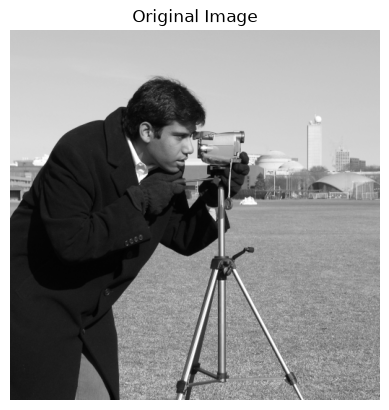

MSE Degraded Image: 0.0017886332052612218


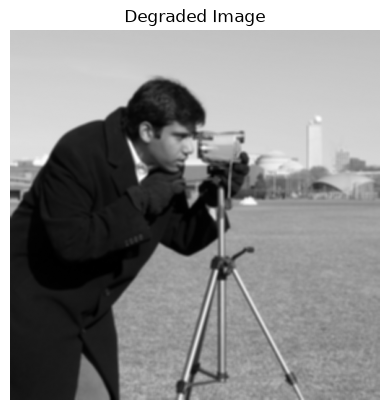

MSE Noised Image: 0.0026779033140038955


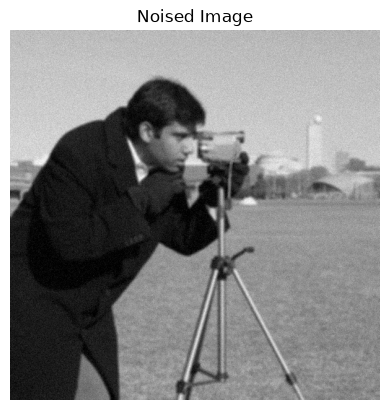

MSE Inverse Filter: 0.010262890539274483


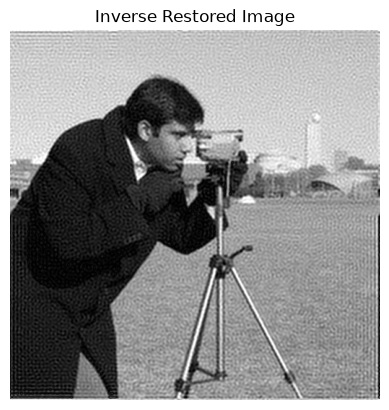

MSE Wiener Filter: 0.01663625298913818


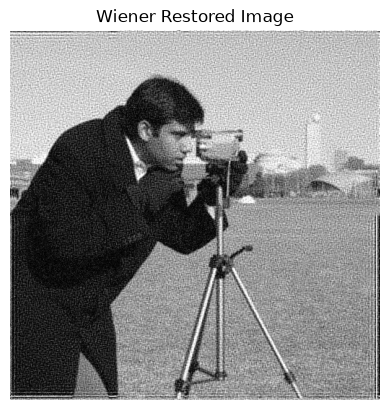

MSE Richardson-Lucy Filter: 0.008538458083316684


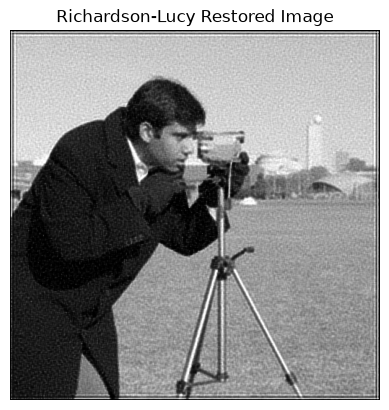

MSE Tikhonov Regularization: 0.011193377092347134


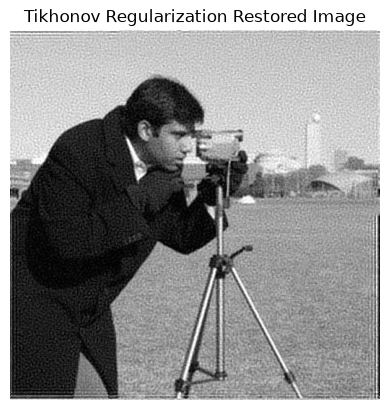

In [67]:
#image = plt.imread(IMG_PATH)
image = data.camera()

# Greyscale conversion if the image is RGB
if image.ndim == 3:
    image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

#convert image to float64 for processing
image = image.astype(np.float64)

# Normalize to [0, 1]
if image.max() > 1:
    image /= 255.0

ShowImage(image, 'Original Image')

#degradation_model = MotionBlurKernel(20, 30)

degradation_model = GaussianBlurKernel(5, 2.0)

degraded_image = ApplyDegradation(image, degradation_model)
print("MSE Degraded Image:", mean_squared_error(image, degraded_image))

ShowImage(degraded_image, 'Degraded Image')

noised_image = AddGaussianNoise(degraded_image, 0, 0.03)
print("MSE Noised Image:", mean_squared_error(image, noised_image))

ShowImage(noised_image, 'Noised Image')

inverse_restored_image = InverseFilter(noised_image, degradation_model, threshold=0.15)
print("MSE Inverse Filter:", mean_squared_error(image, inverse_restored_image))

ShowImage(inverse_restored_image, 'Inverse Restored Image')

wiener_restored_image = WienerFilter(noised_image, degradation_model, K=0.01)
print("MSE Wiener Filter:", mean_squared_error(image, wiener_restored_image))

ShowImage(wiener_restored_image, 'Wiener Restored Image')

psf = degradation_model  # Point Spread Function (PSF) is the degradation kernel

richardson_lucy_restored_image = restoration.richardson_lucy(noised_image, psf, num_iter=20)
print("MSE Richardson-Lucy Filter:", mean_squared_error(image, richardson_lucy_restored_image))
ShowImage(richardson_lucy_restored_image, 'Richardson-Lucy Restored Image')

tikhonov_restored_image = TikhonovRestore(noised_image, degradation_model, alpha=0.005)
print("MSE Tikhonov Regularization:", mean_squared_error(image, tikhonov_restored_image))
ShowImage(tikhonov_restored_image, 'Tikhonov Regularization Restored Image')

El motion blur es un tipo de degradación producido por el movimiento relativo entre la cámara y la escena durante el tiempo de exposición. En este ejemplo se simuló un movimiento horizontal mediante una función de dispersión puntual (PSF) lineal de 20 píxeles con un angulo de 30 grados. La imagen degradada se obtuvo convolucionando la imagen original con dicha PSF. 

Para alternar entre los distintos kernels de degradacion se puede modificar la linea donde se crea la variable degradation_kernel

Los métodos de regularización permiten abordar el problema de restauración de imágenes cuando la inversión directa del sistema de degradación resulta inestable, especialmente ante la presencia de ruido. En este ejemplo se utilizó regularización de Tikhonov, incorporando un operador Laplaciano y un parámetro de regularización que controla el compromiso entre la recuperación de detalles y la amplificación del ruido. Además, se aplicó el método iterativo Richardson–Lucy, que obtiene progresivamente una estimación de la imagen original mediante sucesivas iteraciones. Ambos métodos fueron aplicados sobre una imagen degradada mediante desenfoque y ruido gaussiano. Finalmente, los resultados se compararon con la imagen original utilizando el error cuadrático medio (MSE), permitiendo evaluar cuantitativamente la capacidad de restauración de cada método.

## Image Restoration

In this part of the notebook we will show an example of interference restoration using frequency domain filtering

(294, 294)


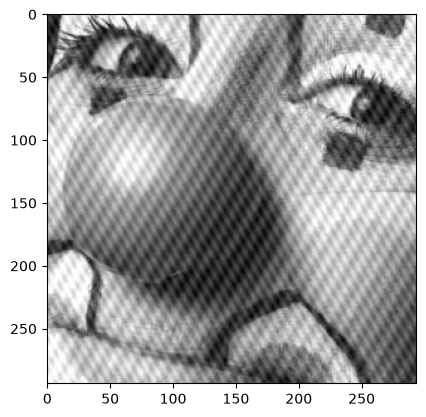

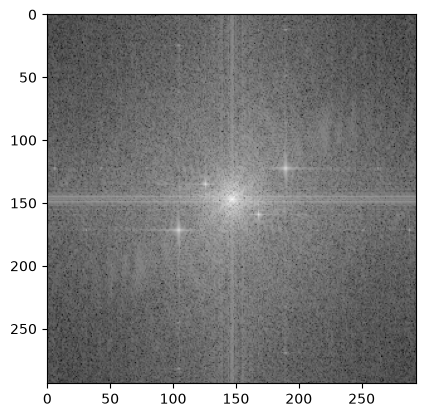

In [68]:
image = plt.imread('clown.jpg')

#grayscale

image = np.mean(image, axis=2)
plt.imshow(image, cmap='gray')

print(image.shape)

fft = np.fft.fftshift(np.fft.fft2(image))
#plot fft
plt.figure()
plt.imshow(20*np.log(np.abs(fft)), cmap='gray', vmin=30, vmax=300)

In [73]:
def gaussian_notch_filter(shape, notch_frequencies, sigma=5):
    """
    Create a Gaussian notch-reject filter.

    Parameters
    ----------
    shape : tuple
        Image shape (rows, cols)

    notch_frequencies : list of (u, v)
        Frequencies to remove.
        Coordinates are relative to the CENTER of the FFT.

    sigma : float
        Width of each notch.

    Returns
    -------
    H : ndarray
        Notch filter in FFT-shifted coordinates.
    """

    rows, cols = shape

    u = np.arange(-cols // 2, cols // 2)
    v = np.arange(-rows // 2, rows // 2)

    U, V = np.meshgrid(u, v)

    H = np.ones(shape)

    for u0, v0 in notch_frequencies:

        # Distance to positive-frequency notch
        D1_squared = (
            (U - u0)**2 +
            (V - v0)**2
        )

        # Distance to symmetric negative-frequency notch
        D2_squared = (
            (U + u0)**2 +
            (V + v0)**2
        )

        # Gaussian notch pair
        notch = (
            1
            - np.exp(-D1_squared / (2 * sigma**2))
        )

        notch *= (
            1
            - np.exp(-D2_squared / (2 * sigma**2))
        )

        H *= notch

    return H


def gaussian_lowpass_filter(shape, D0):
    """
    Create a Gaussian low-pass filter.

    D0 controls the cutoff frequency.

    Smaller D0 -> stronger smoothing
    Larger D0  -> more high frequencies preserved
    """

    rows, cols = shape

    # Frequency coordinates centered at (0, 0)
    u = np.arange(-cols // 2, cols // 2)
    v = np.arange(-rows // 2, rows // 2)

    U, V = np.meshgrid(u, v)

    # Distance from frequency origin
    D = np.sqrt(U**2 + V**2)

    # Gaussian low-pass filter
    H = np.exp(
        -(D**2) / (2 * D0**2)
    )

    return H

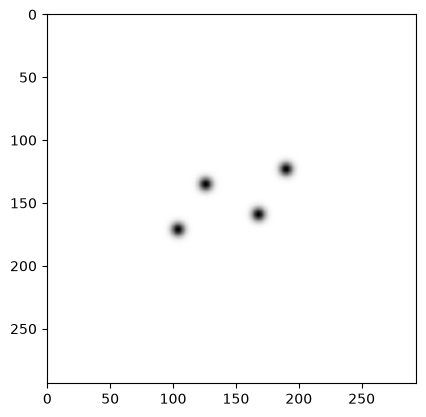

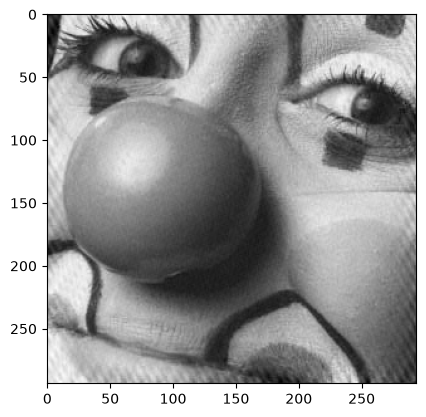

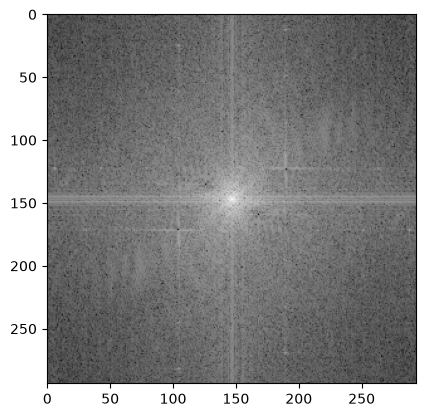

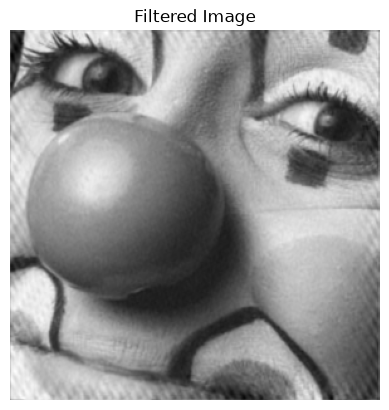

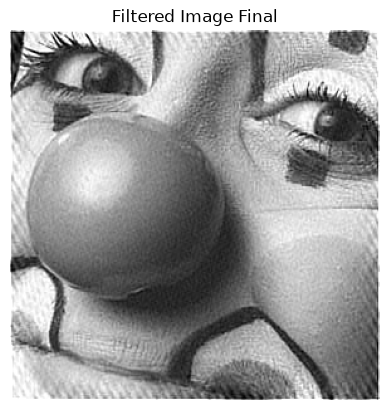

In [81]:
notches = [
    (43, -24),
    (21, 12)
    #(43, -135),
    #(43, 123)
]


filter = gaussian_notch_filter(
    image.shape,
    notches,
    sigma=3.7
)


#filter fft
plt.figure()
#plt.imshow(20*np.log(np.abs(np.fft.fftshift(np.fft.fft2(filter)))), cmap='gray')
plt.imshow(filter, cmap='gray')

fft = np.fft.fftshift(np.fft.fft2(image))

filtered_image = np.fft.ifft2(np.fft.ifftshift(fft * filter)).real
plt.figure()
plt.imshow(np.abs(filtered_image), cmap='gray')

# print filtered fft
fft_filtered = np.fft.fftshift(np.fft.fft2(filtered_image))
plt.figure()
plt.imshow(20*np.log(np.abs(fft_filtered)), cmap='gray', vmin=30, vmax=300)


#low pass image

lowpass_filter = gaussian_lowpass_filter(image.shape, D0=85)

filtered_image = np.fft.ifft2(np.fft.ifftshift(fft * filter * lowpass_filter)).real

plt.figure()
plt.imshow(np.abs(filtered_image), cmap='gray')

def ApplyFilter(img, filter):
    return sp.convolve2d(img, filter, mode='same')


ShowImage(filtered_image, 'Filtered Image')

filter = np.array([
    [-0.1667, -0.6667, -0.1667],
    [-0.6667,  4.3333, -0.6667],
    [-0.1667, -0.6667, -0.1667]
])


filtered_final = ApplyFilter(filtered_image, filter)
filtered_final = np.clip(filtered_final, 0, 255)  # Clip values to valid range
ShowImage(filtered_final, 'Filtered Image Final')